# Simulation of a Single Transmon with VQE and VQD

Calculate the effective circuit parameters, construct the charge Hamiltonian, find its ground and first excited states, and calculate the transition frequency. The four-step workflow follows the original VQE procedure. The final section adds VQD.

| Section | Calculation |
|---|---|
| Parameter conversion | Use inductance and linear circuit frequency to calculate effective capacitance, charging energy, and Josephson energy. |
| 3.1 Step 1 | Build the charge Hamiltonian and Pauli observable, calculate the exact reference, and define the ground-state ansatz. |
| 3.2 Step 2 | Transpile the circuit and map the observable. |
| 3.3 Step 3 | Run ground-state VQE with seeded parameters. |
| 3.4 Step 4 | Validate the returned ground state. |
| 4.1 to 4.4 | Refine the ground state, use VQD for the first excited state, and validate the transition. |

**Parameter conversion**

The inputs are the Josephson small-signal inductance $L_J=10$ nH and the linear circuit-mode frequency $f_{\rm lin}=5.21015$ GHz. Use the single-mode LC equivalent,

$$
C_{\rm eff}=\frac{1}{L_J(2\pi f_{\rm lin})^2}.
$$

Convert that capacitance and inductance into the physical energy scales,

$$
E_C=\frac{e^2}{2C_{\rm eff}},
\qquad
E_J=\frac{(\Phi_0/2\pi)^2}{L_J},
\qquad
\Phi_0=\frac{h}{2e}.
$$

The code stores both energies divided by $h$ in GHz. These inputs give $C_{\rm eff}\approx93.31$ fF, $E_C/h\approx0.207585$ GHz, and $E_J/h\approx16.346151$ GHz.

**Simulation assumptions**

- The capacitance is inferred from the linear frequency and inductance using a single-mode circuit equivalent. It includes the effective electromagnetic loading represented by that frequency.
- Use the full cosine charge Hamiltonian with zero offset charge and $N=8$. Seventeen physical charge states require five qubits with padding.
- Ground-state VQE uses the original real-rotation ansatz. Its result is refined with a complete real physical-charge ansatz before deflation.
- Qiskit StatevectorEstimator supplies noiseless energy and overlap expectations. The refinement and VQD optimizations use analytic simulation gradients.
- Numerical diagonalization supplies validation references. The linear input frequency and nonlinear quantum transition are reported separately.
- All plots display inline.

The first code cell imports the libraries. The second performs the parameter conversions and prints their units.


In [1]:
# %pip install qiskit==2.2.3 numpy==2.3.4 scipy==1.16.3 matplotlib==3.10.7
# Tested with Python 3.14.0 and the versions above.
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize
from scipy.constants import e as electron_charge, h as planck_h

from qiskit.circuit.library import efficient_su2
from qiskit.primitives import StatevectorEstimator
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.quantum_info import Operator, SparsePauliOp, Statevector
from qiskit.transpiler import CouplingMap
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager


In [2]:
# Physical inputs from the linear circuit simulation.
L_J_nH = 10.0          # Josephson small-signal inductance [nH].
f_linear_GHz = 5.21015 # Linear circuit-mode frequency [GHz].
n_g = 0.0             # Offset charge in Cooper-pair units [dimensionless].
N = 8                 # Charge cutoff [integer].

assert np.all(np.isfinite([L_J_nH, f_linear_GHz, n_g]))
assert L_J_nH > 0 and f_linear_GHz > 0
assert isinstance(N, int) and N >= 1

# Infer the capacitance of the single-mode LC equivalent.
L_J = L_J_nH * 1e-9  # Inductance [H].
f_linear = f_linear_GHz * 1e9  # Frequency [Hz].
C_effective = 1 / (L_J * (2 * np.pi * f_linear)**2)  # Capacitance [F].

# Convert physical energies to E/h in GHz for the charge Hamiltonian.
E_C = electron_charge**2 / (2 * C_effective * planck_h) / 1e9
E_J = (
    (planck_h / (4 * np.pi * electron_charge))**2
    / (L_J * planck_h)
    / 1e9
)
f_linear_check_GHz = np.sqrt(8 * E_J * E_C)  # Frequency [GHz].
assert np.isclose(f_linear_check_GHz, f_linear_GHz, atol=1e-10, rtol=0)

seed = 42
ansatz_reps = 4
max_evals = 8000
optimizer_tol = 1e-7  # Final COBYLA trust-region radius [radians].

print(f"Inductance:             {L_J_nH:.6f} nH")
print(f"Linear input frequency: {f_linear_GHz:.6f} GHz")
print(f"Effective capacitance:  {C_effective * 1e15:.6f} fF")
print(f"E_C/h:                  {E_C:.9f} GHz")
print(f"E_J/h:                  {E_J:.9f} GHz")
print(f"E_J / E_C:              {E_J / E_C:.6f}")
print(f"Linear frequency check: {f_linear_check_GHz:.6f} GHz")


Inductance:             10.000000 nH
Linear input frequency: 5.210150 GHz
Effective capacitance:  93.312497 fF
E_C/h:                  0.207584515 GHz
E_J/h:                  16.346151281 GHz
E_J / E_C:              78.744560
Linear frequency check: 5.210150 GHz


### 3.1 Step 1: Map the problem to quantum circuits and operators

The charge basis diagonalizes the electrostatic energy of the island. The integer $n$ counts excess Cooper pairs. Josephson tunnelling transfers one Cooper pair across the junction, so the cosine couples neighbouring charge states. With all energies divided by $h$, the truncated matrix is

$$
H_{nm}
=4(E_C/h)(n-n_g)^2\delta_{nm}
-\frac{E_J}{2h}\bigl(\delta_{n,m+1}+\delta_{n,m-1}\bigr),
\qquad -N\le n,m\le N.
$$

Encode $|n\rangle$ as the computational basis state with integer index $n+N$. For $d=2N+1$ charge states, use $q=\lceil\log_2 d\rceil$ qubits and $D=2^q$ basis states. The embedded matrix is $A=H\oplus E_{\rm pad}I_{D-d}$. Its two blocks have zero coupling. Choose $E_{\rm pad}=\min_n H_{nn}+E_J/h$. A physical basis state has energy $\min_n H_{nn}$, so the variational principle puts the physical ground energy strictly below the padding level.

The code expands $A=\sum_P c_P P$ in tensor products of $I,X,Y,Z$, with $c_P=2^{-q}\operatorname{Tr}(PA)$. The code prints the current dimensions and Pauli reconstruction check. [Qiskit `SparsePauliOp` documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.quantum_info.SparsePauliOp)

In [3]:
# The electrostatic cost is diagonal in the number of excess Cooper pairs.
n = np.arange(-N, N + 1)
d = n.size
charging = 4 * E_C * (n - n_g)**2  # Electrostatic cost [GHz]

# Each charge shift in cos(phi) has weight 1/2. The two off-diagonals
# describe tunnelling in both directions, with hops ending at the cutoff.
hopping = np.full(d - 1, -E_J / 2)  # Nearest-neighbour matrix elements [GHz]
H = np.diag(charging) + np.diag(hopping, 1) + np.diag(hopping, -1)

num_qubits = int(d - 1).bit_length()
D = 2**num_qubits

# The cheapest charge state gives an upper bound on the physical ground energy.
# Putting the padding above that bound keeps the ground state in the charge block.
E_pad = charging.min() + E_J  # Padding energy [GHz]
A = E_pad * np.eye(D)
A[:d, :d] = H

# Reconstruct the full matrix to check the physical block and the padding.
hamiltonian = SparsePauliOp.from_operator(Operator(A), atol=1e-12, rtol=0)
assert np.allclose(hamiltonian.to_matrix(), A, atol=1e-10, rtol=0)
print(f"{d} charge states, {num_qubits} qubits, {D - d} padding states")
print(f"Pauli reconstruction passed ({len(hamiltonian)} terms).")


17 charge states, 5 qubits, 15 padding states
Pauli reconstruction passed (78 terms).


#### Exact reference energy

Diagonalize the physical charge block $H$ before building the ansatz, following the order of the example. The lowest eigenvalue is the reference for the chosen cutoff. The code prints the current exact energy. The optimizer uses only the Pauli observable and trial circuit.

In [4]:
# Use the physical block so the benchmark contains only charge states.
eigenvalues, _ = np.linalg.eigh(H)
E_exact = float(eigenvalues[0])  # Ground-state energy divided by h [GHz]
print(f"Exact ground-state energy = {E_exact:.12f} GHz")


Exact ground-state energy = -13.794074162800 GHz


#### Ansatz

Prepare $|\psi(\vec{\theta})\rangle=U_{\rm var}(\vec{\theta})|0\rangle^{\otimes q}$. Because $H$ is real symmetric, a ground eigenvector can be chosen real. The $R_Y$ gates vary real amplitudes, and the circular CX layers let the bits encoding charge become correlated. The code prints the current parameter count and circuit. [Qiskit `efficient_su2` documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.circuit.library.efficient_su2)

In [5]:
# RY varies the real amplitudes. Circular CX layers let the qubits
ansatz = efficient_su2(
    hamiltonian.num_qubits,
    su2_gates=["ry"],
    entanglement="circular",
    reps=ansatz_reps,
)
num_params = ansatz.num_parameters  # Each parameter is an angle in radians.
print(f"Logical ansatz: {num_params} parameters, depth {ansatz.depth()}")
print(ansatz.draw(output="text", fold=105))


Logical ansatz: 25 parameters, depth 25
     ┌──────────┐┌───┐     ┌──────────┐                                    ┌───┐     ┌───────────┐»
q_0: ┤ Ry(θ[0]) ├┤ X ├──■──┤ Ry(θ[5]) ├────────────────────────────────────┤ X ├──■──┤ Ry(θ[10]) ├»
     ├──────────┤└─┬─┘┌─┴─┐└──────────┘┌──────────┐                        └─┬─┘┌─┴─┐└───────────┘»
q_1: ┤ Ry(θ[1]) ├──┼──┤ X ├─────■──────┤ Ry(θ[6]) ├──────────────────────────┼──┤ X ├──────■──────»
     ├──────────┤  │  └───┘   ┌─┴─┐    └──────────┘┌──────────┐              │  └───┘    ┌─┴─┐    »
q_2: ┤ Ry(θ[2]) ├──┼──────────┤ X ├─────────■──────┤ Ry(θ[7]) ├──────────────┼───────────┤ X ├────»
     ├──────────┤  │          └───┘       ┌─┴─┐    └──────────┘┌──────────┐  │           └───┘    »
q_3: ┤ Ry(θ[3]) ├──┼──────────────────────┤ X ├─────────■──────┤ Ry(θ[8]) ├──┼────────────────────»
     ├──────────┤  │                      └───┘       ┌─┴─┐    ├──────────┤  │                    »
q_4: ┤ Ry(θ[4]) ├──■──────────────────────────────────┤ X ├─

### 3.2 Step 2: Optimize for target hardware

Use a local `GenericBackendV2` target to specify which gates are available and which qubits can interact. The line topology requires routing some of the circular CX connections. Expect a target with the current qubit count and `u` and `cx` as its unitary basis gates. [Qiskit `GenericBackendV2` documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.providers.fake_provider.GenericBackendV2)

In [6]:
backend = GenericBackendV2(
    num_qubits=num_qubits,
    basis_gates=["u", "cx"],
    coupling_map=CouplingMap.from_line(num_qubits),
    seed=seed,
    noise_info=False,
)
target = backend.target
print(f"Local target: {target.num_qubits} qubits, operations {backend.operation_names}")


Local target: 5 qubits, operations ['u', 'cx', 'reset', 'delay', 'measure']


#### Transpile the ansatz

Translate the logical circuit into the target's instruction set and route its two-qubit gates. The parameter set should survive transpilation. Expect the transpiled depth, gate counts, and circuit diagram.

In [7]:
# Compile the circuit once so every objective evaluation uses the same layout.
pm = generate_preset_pass_manager(
    target=target, optimization_level=3, seed_transpiler=seed
)
ansatz_isa = pm.run(ansatz)
assert set(ansatz_isa.parameters) == set(ansatz.parameters)

print(f"Transpiled depth: {ansatz_isa.depth()}")
print(f"Transpiled gate counts: {dict(ansatz_isa.count_ops())}")
print(ansatz_isa.draw(output="text", fold=105, idle_wires=False))


Transpiled depth: 66
Transpiled gate counts: {'cx': 68, 'u': 37}
global phase: 5.6338
         ┌─────────────┐                              ┌───┐                    ┌───┐»
q_4 -> 0 ┤ U(θ[4],0,0) ├──■───────────────────────────┤ X ├────────────■───────┤ X ├»
         ├─────────────┤┌─┴─┐     ┌─────────────┐     └─┬─┘          ┌─┴─┐     └─┬─┘»
q_0 -> 1 ┤ U(θ[0],0,0) ├┤ X ├──■──┤ U(θ[5],0,0) ├───────■────────────┤ X ├───────■──»
         ├─────────────┤└───┘┌─┴─┐└─────────────┘┌─────────────┐     └───┘          »
q_1 -> 2 ┤ U(θ[1],0,0) ├─────┤ X ├───────■───────┤ U(θ[6],0,0) ├────────────────────»
         ├─────────────┤     └───┘     ┌─┴─┐     └─────────────┘┌─────────────┐     »
q_2 -> 3 ┤ U(θ[2],0,0) ├───────────────┤ X ├────────────■───────┤ U(θ[7],0,0) ├──■──»
         ├─────────────┤               └───┘          ┌─┴─┐     └─────────────┘┌─┴─┐»
q_3 -> 4 ┤ U(θ[3],0,0) ├──────────────────────────────┤ X ├────────────────────┤ X ├»
         └─────────────┘                              

#### Apply the layout to the Hamiltonian

A logical qubit can finish on a different wire after routing. Apply the circuit layout to the Pauli strings so each term still acts on the intended charge bits. Expect the list mapping logical qubits to final wires. [Qiskit `SparsePauliOp.apply_layout` documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.quantum_info.SparsePauliOp#apply_layout)

In [8]:
# Use the circuit's full layout, including any permutation from routing.
hamiltonian_isa = hamiltonian.apply_layout(ansatz_isa.layout)
assert hamiltonian_isa.num_qubits == ansatz_isa.num_qubits
print(f"Logical-to-final qubits: {ansatz_isa.layout.final_index_layout()}")


Logical-to-final qubits: [4, 3, 2, 1, 0]


### 3.3 Step 3: Execute on target hardware

#### 3.3.1 Reporting out values

For this local implementation, `StatevectorEstimator` computes the expectation value of the layout-adjusted Pauli operator with no sampling noise. COBYLA minimizes the equivalent logical energy

$$
E_{\rm var}(\vec{\theta})
=\langle\psi(\vec{\theta})|A|\psi(\vec{\theta})\rangle
\ge E_{\rm exact},
$$

up to floating-point precision. The inequality follows because the lowest eigenvalue of $A$ belongs to the physical block. The cost function records every trial energy, while the callback records the energy that COBYLA reports at each iteration. The next cell defines these functions and initializes the histories. It produces no printed output. [Qiskit `StatevectorEstimator` documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.primitives.StatevectorEstimator)

In [9]:
def cost_func(params, ansatz, hamiltonian, estimator):
    """Return the trial energy [GHz] and record this objective evaluation."""

    # The Estimator binds params in the circuit's parameter order.
    pub = (ansatz, hamiltonian, params)
    energy = float(estimator.run([pub]).result()[0].data.evs.item())

    # Store a copy because an optimizer can reuse the input array.
    cost_history_dict["prev_vector"] = np.copy(params)
    cost_history_dict["cost_history"].append(energy)
    return energy


def record_iteration(intermediate_result):
    """Record the reported iteration energy [GHz] without another evaluation."""
    cost_history_dict["iters"].append(intermediate_result.nit)
    cost_history_dict["iteration_energy"].append(float(intermediate_result.fun))


cost_history_dict = {
    "prev_vector": None,
    "cost_history": [],
    "iters": [],
    "iteration_energy": [],
}


#### Initial parameters

Draw $\vec{\theta}_0$ uniformly from $[0,2\pi)$ as in the procedure, using a fixed seed for reproducibility. Expect a confirmation of the current number of initial angles.

In [10]:
rng = np.random.default_rng(seed)
x0 = 2 * np.pi * rng.random(num_params)  # Initial angles [radians]
print(f"Initialised {x0.size} angles.")


Initialised 25 angles.


#### Run the classical optimizer

COBYLA varies the angles using only energy evaluations. SciPy drives the iteration loop and calls `record_iteration` with its current result. In the pinned SciPy version, the `maxiter` option caps objective evaluations. The execution cell stores the result in `res`, and the next cell prints the termination message, final energy, and evaluation count. [SciPy COBYLA documentation](https://docs.scipy.org/doc/scipy-1.16.1/reference/optimize.minimize-cobyla.html)

In [11]:
# Clear the histories so rerunning this cell starts a fresh optimization.
cost_history_dict["prev_vector"] = None
for key in ("cost_history", "iters", "iteration_energy"):
    cost_history_dict[key].clear()

# Zero precision requests a noiseless statevector expectation value.
estimator = StatevectorEstimator(default_precision=0.0, seed=seed)
res = minimize(
    cost_func,
    x0,
    args=(ansatz_isa, hamiltonian_isa, estimator),
    method="COBYLA",
    callback=record_iteration,
    options={"maxiter": max_evals, "tol": optimizer_tol},
)


In [12]:
print(res)


 message: Return from COBYLA because the objective function has been evaluated MAXFUN times.
 success: False
  status: 3
     fun: -13.763120732928535
       x: [ 6.312e+00  1.543e+00 ...  4.591e+00  4.712e+00]
    nfev: 8000
   maxcv: 0.0


### 3.4 Step 4: Post-process results

Use the energy at the solution returned by COBYLA and compute $\lvert E_{\rm VQE}-E_{\rm exact}\rvert$. Check the evaluation count, then bind the solution to the logical circuit to measure its padding probability and independently verify the layout-adjusted energy.

As a physics sanity check, expanding the cosine to quartic order gives the ground-state estimate

$$
E_0/h \approx -E_J/h + \sqrt{2(E_J/h)(E_C/h)} - \frac{E_C}{4h}.
$$

Check the reported VQE error and padding. The quartic approximation is a leading large-ratio estimate whose error is checked numerically. [Koch et al., *Charge-insensitive qubit design derived from the Cooper pair box*](https://arxiv.org/abs/cond-mat/0703002)

In [13]:
# The last trial can differ from the point COBYLA returns.
assert len(cost_history_dict["cost_history"]) == res.nfev
last_trial_is_solution = np.array_equal(cost_history_dict["prev_vector"], res.x)

E_vqe = float(res.fun)  # Returned variational energy divided by h [GHz]
absolute_error = abs(E_vqe - E_exact)  # [GHz]

# Bind by parameter identity, then inspect amplitudes in logical charge order.
params_opt = dict(zip(ansatz_isa.parameters, res.x))
psi_opt = Statevector.from_instruction(ansatz.assign_parameters(params_opt))
p_pad = float(np.sum(np.abs(psi_opt.data[d:])**2))  # Probability [dimensionless]

# Check that layout and parameter binding preserve the energy.
E_logical = float(np.vdot(psi_opt.data, A @ psi_opt.data).real)  # [GHz]
assert np.isclose(E_logical, E_vqe, atol=1e-9, rtol=0)
assert E_vqe >= E_exact - 1e-9

# Compare with the harmonic zero-point energy and first quartic correction.
E_approx = -E_J + np.sqrt(2 * E_J * E_C) - E_C / 4  # [GHz]
print(f"Last trial equals returned solution: {last_trial_is_solution}")
print(f"Exact energy:           {E_exact:.12f} GHz")
print(f"VQE energy:             {E_vqe:.12f} GHz")
print(f"Absolute error:         {absolute_error:.3e} GHz")
print(f"Padding probability:    {p_pad:.3e}")
print(f"Transmon approximation: {E_approx:.12f} GHz")


Last trial equals returned solution: True
Exact energy:           -13.794074162800 GHz
VQE energy:             -13.763120732929 GHz
Absolute error:         3.095e-02 GHz
Padding probability:    1.036e-07
Transmon approximation: -13.792972409307 GHz


#### Convergence plot

Plot the energy reported by the callback against the COBYLA iteration number. Expect the curve to fall towards the dashed horizontal line at the exact ground energy. The callback trace and the final `res.fun` can end at slightly different energies.

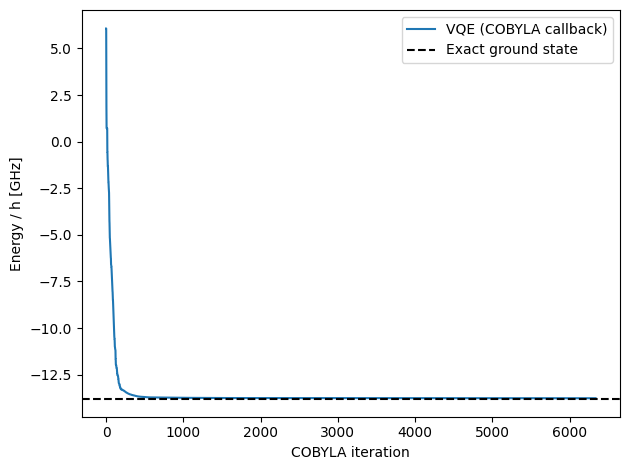

In [14]:
# Plot optimizer iterations separately from individual trial evaluations.
fig, ax = plt.subplots()
ax.plot(
    cost_history_dict["iters"],
    cost_history_dict["iteration_energy"],
    label="VQE (COBYLA callback)",
)
ax.axhline(E_exact, color="black", linestyle="--", label="Exact ground state")
ax.set_xlabel("COBYLA iteration")
ax.set_ylabel("Energy / h [GHz]")
ax.legend()
fig.tight_layout()
plt.show()


## Ground state VQE results

The heuristic VQE run at the effective ADS-derived parameters gives -13.763120732929 GHz. Its ground-energy error is about 30.953 MHz. The appended expressive real-charge ansatz refines this state before deflation.

The effective one-mode Hamiltonian is an approximation to the full distributed circuit. The following section distinguishes algorithm agreement from the physical reduction.


## 4. Variational Quantum Deflation and the first transition

VQD minimizes

$$
F_1(\theta)=\langle\psi(\theta)|A_{\rm VQD}|\psi(\theta)\rangle
+\beta|\langle\psi_0|\psi(\theta)\rangle|^2.
$$

The penalty suppresses the ground component. With an exact ground reference, $\beta>E_1-E_0$ raises that level above the first excited state. [Higgott et al., VQD](https://arxiv.org/abs/1805.08138)

| Step | Extension |
|---|---|
| 4.1 Step 1 | Define padding, the penalty, and the trial circuits. |
| 4.2 Step 2 | Transpile and map the observables. |
| 4.3 Step 3 | Refine the ground state and optimize VQD. |
| 4.4 Step 4 | Validate energies and the transition, and plot inline. |

**Assumptions and deviations**

- Use the effective parameters inferred from the full-layout ADS mode, with a ratio about 78.74.
- Refine the heuristic VQE result before using it as the deflation reference.
- Use a real ansatz spanning the physical charge states, with no padding population.
- Use L-BFGS-B with analytic simulation gradients. Qiskit Estimator supplies energies and overlaps. Exact eigenvectors are reserved for validation.
- Display every figure inline.

### 4.1 Step 1  Define the VQD operator and penalty

A two-charge-state trial subspace supplies an upper bound on $E_1$. Gershgorin bounds supply a lower bound on $E_0$. Set beta from their difference and raise padding above the excited-state upper bound. Expect the ratio, padding energy and beta.


In [15]:
# Additional VQD imports use the same pinned Qiskit and SciPy versions.
from time import perf_counter
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import RYGate

vqd_seed = seed + 100
vqd_maxiter = 800
vqd_maxfun = 2000
vqd_penalty_factor = 1.2  # Dimensionless margin on the gap bound.
assert vqd_penalty_factor > 1

E0_original_vqe = float(E_vqe)  # Previous VQE energy / h [GHz].
ratio_vqd = E_J / E_C
print(f"E_J / E_C = {ratio_vqd:.6f}")

# A two-dimensional trial subspace gives an upper bound on physical E1.
reference_indices = np.argsort(np.diag(H))[:2]
E1_upper = float(np.linalg.eigvalsh(H[np.ix_(
    reference_indices, reference_indices
)])[-1])
# Gershgorin row bounds give a lower bound on physical E0.
E0_lower = float(np.min(
    np.diag(H) - (np.sum(np.abs(H), axis=1) - np.abs(np.diag(H)))
))
beta_vqd = vqd_penalty_factor * (E1_upper - E0_lower)  # [GHz].

# Raise padding above the first physical excited state.
E_pad_vqd = E1_upper + max(E_C, 1.0)  # [GHz].
A_vqd = E_pad_vqd * np.eye(D)
A_vqd[:d, :d] = H
hamiltonian_vqd = SparsePauliOp.from_operator(
    Operator(A_vqd), atol=1e-12, rtol=0
)
assert np.allclose(hamiltonian_vqd.to_matrix(), A_vqd, atol=1e-9, rtol=0)
print(f"VQD padding energy: {E_pad_vqd:.6f} GHz")
print(f"Overlap penalty beta: {beta_vqd:.6f} GHz")


E_J / E_C = 78.744560
VQD padding energy: 9.598783 GHz
Overlap penalty beta: 29.933921 GHz


#### Define the physical-charge ansatz

Controlled real rotations mix a reference charge state with every other retained charge state. The circuit spans normalized real physical vectors up to a global sign.

The amplitude routine also returns $J_{jk}=\partial\psi_j/\partial\theta_k$. The energy gradient is $2J^\mathsf{T}A\psi$. Expect 16 angles per state for the current charge basis.


In [16]:
def build_vqd_ansatz(reference, prefix):
    """Build real rotations spanning the retained physical charge states."""
    targets = [index for index in range(d) if index != reference]
    parameters = ParameterVector(prefix, len(targets))
    circuit = QuantumCircuit(num_qubits)

    # In XOR coordinates, each controlled rotation mixes |0> with one target.
    for index, parameter in zip(targets, parameters):
        mask = reference ^ index
        bits = [bit for bit in range(num_qubits) if mask & (1 << bit)]
        pivot, *tail = bits
        controls = [bit for bit in range(num_qubits) if bit != pivot]
        for bit in tail:
            circuit.cx(pivot, bit)
        circuit.append(
            RYGate(parameter).control(num_qubits - 1, ctrl_state=0),
            [*controls, pivot],
        )
        for bit in reversed(tail):
            circuit.cx(pivot, bit)

    # Restore the original charge encoding after the pair rotations.
    for bit in range(num_qubits):
        if reference & (1 << bit):
            circuit.x(bit)
    return circuit, targets


def vqd_amplitudes(parameters, reference, targets):
    """Return real amplitudes and derivatives with respect to angles [rad]."""
    state = np.zeros(D)
    jacobian = np.zeros((D, len(targets)))
    central = 1.0
    derivative = np.zeros(len(targets))

    for k, (index, angle) in enumerate(zip(targets, parameters)):
        sine, cosine = np.sin(angle / 2), np.cos(angle / 2)
        state[index] = central * sine
        jacobian[index] = derivative * sine
        jacobian[index, k] += central * cosine / 2
        updated = derivative * cosine
        updated[k] -= central * sine / 2
        central *= cosine
        derivative = updated

    state[reference] = central
    jacobian[reference] = derivative
    return state, jacobian


def vqd_initial_angles(vector, reference, targets):
    """Convert a normalized real charge guess into the circuit's angles."""
    vector = np.array(vector, dtype=float, copy=True)
    vector /= np.linalg.norm(vector)
    if vector[reference] < 0:
        vector *= -1

    angles = []
    for k, index in enumerate(targets):
        remaining = np.sqrt(
            vector[reference]**2 + np.sum(vector[targets[k + 1:]]**2)
        )
        angles.append(2 * np.arctan2(vector[index], remaining))
    return np.array(angles)


ground_reference, excited_reference = map(int, reference_indices)
ground_ansatz_vqd, ground_targets = build_vqd_ansatz(ground_reference, "theta_g")
excited_ansatz_vqd, excited_targets = build_vqd_ansatz(excited_reference, "theta_e")
print(f"Physical amplitudes: {d}, angles per state: {d - 1}")


Physical amplitudes: 17, angles per state: 16


### 4.2 Step 2  Optimize for the existing target

Compile both trial circuits and map their energy observables. Check analytic amplitudes against the circuits and a derivative against a finite difference. Expect gate counts and successful assertions.


In [17]:
# Use the existing backend target, preserving the notebook's transpilation step.
pm_vqd = generate_preset_pass_manager(
    target=target, optimization_level=3, seed_transpiler=vqd_seed
)
ground_isa_vqd = pm_vqd.run(ground_ansatz_vqd)
excited_isa_vqd = pm_vqd.run(excited_ansatz_vqd)
ground_hamiltonian_isa = hamiltonian_vqd.apply_layout(ground_isa_vqd.layout)
excited_hamiltonian_isa = hamiltonian_vqd.apply_layout(excited_isa_vqd.layout)

# Check the amplitude model against each actual logical circuit.
for circuit, reference, targets in (
    (ground_ansatz_vqd, ground_reference, ground_targets),
    (excited_ansatz_vqd, excited_reference, excited_targets),
):
    test_angles = np.random.default_rng(vqd_seed).normal(0, 0.1, len(targets))
    test_state, test_jacobian = vqd_amplitudes(test_angles, reference, targets)
    circuit_state = Statevector.from_instruction(
        circuit.decompose().assign_parameters(test_angles)
    ).data
    assert np.allclose(test_state, circuit_state, atol=1e-10, rtol=0)
    shift = np.zeros(len(targets))
    shift[0] = 1e-6
    derivative_check = (
        vqd_amplitudes(test_angles + shift, reference, targets)[0]
        - vqd_amplitudes(test_angles - shift, reference, targets)[0]
    ) / (2e-6)
    assert np.allclose(test_jacobian[:, 0], derivative_check, atol=1e-8, rtol=0)

print("Ground circuit gates:", dict(ground_isa_vqd.count_ops()))
print("Excited circuit gates:", dict(excited_isa_vqd.count_ops()))


Ground circuit gates: {'cx': 853, 'u': 775}
Excited circuit gates: {'cx': 841, 'u': 776}


### 4.3 Step 3  Refine the ground state

Initialize from the previous VQE amplitudes after removing padding and choosing nonnegative amplitudes. Negative Josephson hopping permits a nonnegative ground wavefunction.

Minimize the Estimator energy with L-BFGS-B and analytic simulation gradients. Expect a refined ground energy near -13.794074162800 GHz.


In [18]:
estimator_vqd = StatevectorEstimator(default_precision=0.0, seed=vqd_seed)
vqd_options = {
    "maxiter": vqd_maxiter, "maxfun": vqd_maxfun,
    "ftol": 1e-14, "gtol": 1e-9, "maxls": 40,
}
ground_refinement_history = []

# Negative Josephson hopping permits a nonnegative ground-state wavefunction.
ground_guess = np.abs(psi_opt.data[:d])
assert np.linalg.norm(ground_guess) > 1e-12
ground_start_vqd = vqd_initial_angles(
    ground_guess, ground_reference, ground_targets
)


def ground_refinement_cost(parameters):
    """Return Estimator energy [GHz] and its exact simulation gradient."""
    state, jacobian = vqd_amplitudes(parameters, ground_reference, ground_targets)
    pub = (ground_isa_vqd, ground_hamiltonian_isa, parameters)
    energy = float(estimator_vqd.run([pub]).result()[0].data.evs.item())
    gradient = 2 * jacobian.T @ (A_vqd @ state)
    return energy, gradient


def ground_refinement_callback(intermediate_result):
    """Record optimizer iterations and their ground energies [GHz]."""
    ground_refinement_history.append(float(intermediate_result.fun))


ground_start_time = perf_counter()
ground_refinement_res = minimize(
    ground_refinement_cost, ground_start_vqd, jac=True,
    method="L-BFGS-B", callback=ground_refinement_callback, options=vqd_options,
)
ground_refinement_seconds = perf_counter() - ground_start_time
ground_state_vqd, _ = vqd_amplitudes(
    ground_refinement_res.x, ground_reference, ground_targets
)
E0_refined = float(ground_state_vqd @ A_vqd @ ground_state_vqd)  # [GHz].

print(ground_refinement_res.message)
print(f"Original VQE E0: {E0_original_vqe:.12f} GHz")
print(f"Refined E0:      {E0_refined:.12f} GHz")
print(f"Refinement time: {ground_refinement_seconds:.3f} s")


CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Original VQE E0: -13.763120732929 GHz
Refined E0:      -13.794074162800 GHz
Refinement time: 0.542 s


#### Minimize the deflated cost

Build $P_0=|\psi_0\rangle\langle\psi_0|$ from the refined variational state. Estimate its expectation alongside the physical energy.

Initialize from $(\hat n-\langle\hat n\rangle)|\psi_0\rangle$, a charge-excited trial orthogonal to the reference. Minimize $F_1=E+\beta\langle P_0\rangle$. Expect physical excited energy near -8.800796284561 GHz and a small ground overlap.


In [19]:
# The projector penalizes overlap with the refined variational ground state.
ground_projector = np.outer(ground_state_vqd, ground_state_vqd)
projector_vqd = SparsePauliOp.from_operator(
    Operator(ground_projector), atol=1e-12, rtol=0
)
assert np.allclose(projector_vqd.to_matrix(), ground_projector, atol=1e-9, rtol=0)
projector_isa_vqd = projector_vqd.apply_layout(excited_isa_vqd.layout)

# Charge applied to the ground state supplies an excited-state trial.
mean_charge = float(np.sum(n * ground_state_vqd[:d]**2))
excited_guess = (n - mean_charge) * ground_state_vqd[:d]
if np.linalg.norm(excited_guess) < 1e-12:
    excited_guess = np.eye(d)[excited_reference].copy()
excited_guess += np.random.default_rng(vqd_seed).normal(0, 1e-5, d)
excited_guess -= ground_state_vqd[:d] * (ground_state_vqd[:d] @ excited_guess)
assert np.linalg.norm(excited_guess) > 1e-12
excited_start_vqd = vqd_initial_angles(
    excited_guess, excited_reference, excited_targets
)
vqd_history = {"cost": [], "energy": [], "overlap": []}


def excited_metrics(parameters):
    """Return the physical energy [GHz] and squared ground overlap."""
    state, _ = vqd_amplitudes(parameters, excited_reference, excited_targets)
    energy = float(state @ A_vqd @ state)
    overlap = float((ground_state_vqd @ state)**2)
    return energy, overlap


def vqd_cost(parameters):
    """Return deflated cost [GHz] and its exact simulation gradient."""
    state, jacobian = vqd_amplitudes(parameters, excited_reference, excited_targets)
    pub = (
        excited_isa_vqd,
        [excited_hamiltonian_isa, projector_isa_vqd],
        parameters,
    )
    energy, overlap = np.asarray(
        estimator_vqd.run([pub]).result()[0].data.evs
    ).ravel()
    effective_action = (
        A_vqd @ state
        + beta_vqd * ground_state_vqd * (ground_state_vqd @ state)
    )
    return float(energy + beta_vqd * overlap), 2 * jacobian.T @ effective_action


def vqd_callback(intermediate_result):
    """Track deflated cost, physical energy, and orthogonality by iteration."""
    energy, overlap = excited_metrics(intermediate_result.x)
    vqd_history["cost"].append(float(intermediate_result.fun))
    vqd_history["energy"].append(energy)
    vqd_history["overlap"].append(overlap)


vqd_start_time = perf_counter()
vqd_res = minimize(
    vqd_cost, excited_start_vqd, jac=True, method="L-BFGS-B",
    callback=vqd_callback, options=vqd_options,
)
vqd_seconds = perf_counter() - vqd_start_time
excited_state_vqd, _ = vqd_amplitudes(
    vqd_res.x, excited_reference, excited_targets
)
E1_vqd, final_overlap_vqd = excited_metrics(vqd_res.x)

print(vqd_res.message)
print(f"Deflated cost:       {vqd_res.fun:.12f} GHz")
print(f"Physical E1:         {E1_vqd:.12f} GHz")
print(f"Ground overlap:      {final_overlap_vqd:.3e}")
print(f"VQD optimization:    {vqd_seconds:.3f} s")


CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Deflated cost:       -8.800796284561 GHz
Physical E1:         -8.800796284561 GHz
Ground overlap:      1.112e-16
VQD optimization:    1.652 s


### 4.4 Step 4  Calculate the transition frequency

Energies are stored divided by $h$ in GHz, so

$$f_{01}^{\rm VQD}=E_1^{\rm VQD}-E_0^{\rm refined}.$$

No extra factor of $h$ or $2\pi$ is needed. Compare individual energies, fidelities and the transition with NumPy. With an approximate reference, unpenalized VQD energy need not be an upper bound on exact $E_1$. Expect a transition near 4.99327787824 GHz.


In [20]:
# Exact eigensystems are used here for validation, after VQD optimization.
exact_levels_vqd, exact_vectors_vqd = np.linalg.eigh(H)
E0_exact_vqd, E1_exact_vqd = map(float, exact_levels_vqd[:2])
f01_vqd = E1_vqd - E0_refined  # Transition frequency [GHz].
f01_exact = E1_exact_vqd - E0_exact_vqd  # [GHz].
f01_error = abs(f01_vqd - f01_exact)  # [GHz].
alpha_full_cosine_GHz = float(
    exact_levels_vqd[2] - 2 * exact_levels_vqd[1] + exact_levels_vqd[0]
)  # Exact-model anharmonicity [GHz].

# Verify state energies, parameter layout, and the penalty bookkeeping.
assert np.isclose(
    vqd_res.fun, E1_vqd + beta_vqd * final_overlap_vqd,
    atol=1e-8, rtol=0,
)
assert np.isclose(ground_refinement_res.fun, E0_refined, atol=1e-8, rtol=0)
assert np.isclose(np.linalg.norm(ground_state_vqd), 1.0, atol=1e-10)
assert np.isclose(np.linalg.norm(excited_state_vqd), 1.0, atol=1e-10)
assert E_pad_vqd > E1_exact_vqd
assert E0_refined >= E0_exact_vqd - 1e-8

F0_vqd = float(abs(exact_vectors_vqd[:, 0] @ ground_state_vqd[:d])**2)
F1_vqd = float(abs(exact_vectors_vqd[:, 1] @ excited_state_vqd[:d])**2)
deflated_exact_min = float(np.linalg.eigvalsh(
    H + beta_vqd * ground_projector[:d, :d]
)[0])

print(f"E0 exact / refined: {E0_exact_vqd:.12f} / {E0_refined:.12f} GHz")
print(f"E1 exact / VQD:     {E1_exact_vqd:.12f} / {E1_vqd:.12f} GHz")
print(f"E0 absolute error:  {1e6 * abs(E0_refined - E0_exact_vqd):.6f} kHz")
print(f"E1 absolute error:  {1e6 * abs(E1_vqd - E1_exact_vqd):.6f} kHz")
print(f"Ground fidelity:    {F0_vqd:.12f}")
print(f"Excited fidelity:   {F1_vqd:.12f}")
print(f"Deflated cost gap:  {vqd_res.fun - deflated_exact_min:.3e} GHz")
print(f"f01 exact:          {f01_exact:.12f} GHz")
print(f"f01 from VQD:       {f01_vqd:.12f} GHz")
print(f"f01 absolute error: {1e9 * f01_error:.6f} Hz")
print(f"Full-cosine alpha:   {alpha_full_cosine_GHz * 1000:.3f} MHz")


E0 exact / refined: -13.794074162800 / -13.794074162800 GHz
E1 exact / VQD:     -8.800796284561 / -8.800796284561 GHz
E0 absolute error:  0.000000 kHz
E1 absolute error:  0.000000 kHz
Ground fidelity:    1.000000000000
Excited fidelity:   1.000000000000
Deflated cost gap:  -4.619e-14 GHz
f01 exact:          4.993277878240 GHz
f01 from VQD:       4.993277878240 GHz
f01 absolute error: 0.000007 Hz
Full-cosine alpha:   -230.550 MHz


#### Check transition-frequency convergence

Increase the charge cutoff by two and recalculate the exact transition. This tests excited-state truncation separately from optimization error. Compare this shift with the much smaller variational optimization error.


In [21]:
# Excited-state truncation must be checked separately from ground convergence.
n_larger_vqd = np.arange(-(N + 2), N + 3)
hopping_larger_vqd = np.full(n_larger_vqd.size - 1, -E_J / 2)
H_larger_vqd = (
    np.diag(4 * E_C * (n_larger_vqd - n_g)**2)
    + np.diag(hopping_larger_vqd, 1)
    + np.diag(hopping_larger_vqd, -1)
)
larger_levels_vqd = np.linalg.eigvalsh(H_larger_vqd)
f01_larger_vqd = float(larger_levels_vqd[1] - larger_levels_vqd[0])  # [GHz].
print(f"Exact f01 at N={N + 2}: {f01_larger_vqd:.12f} GHz")
print(f"Frequency cutoff shift: {1e9 * (f01_larger_vqd - f01_exact):.6f} Hz")


Exact f01 at N=10: 4.993277821944 GHz
Frequency cutoff shift: -56.296146 Hz


#### Plot convergence and the first transition

Display ground refinement, deflated cost, physical excited energy, charge distributions, ground overlap, and the transition comparison. Use physical energy, excluding the overlap penalty, to calculate the frequency. All plots display inline.


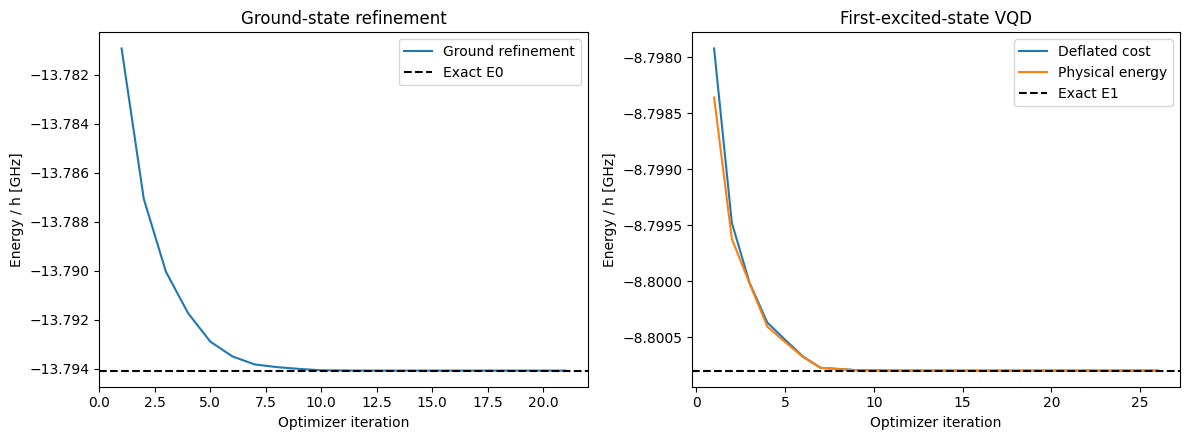

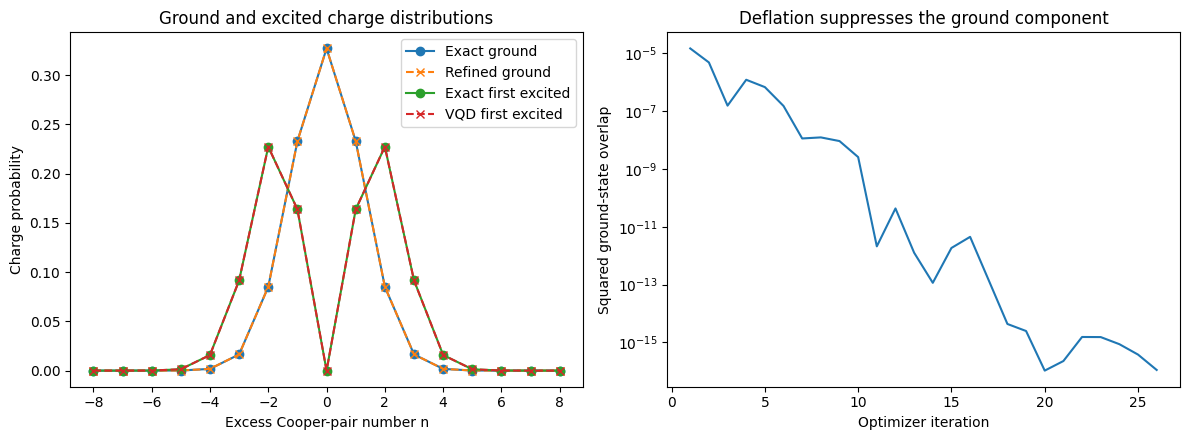

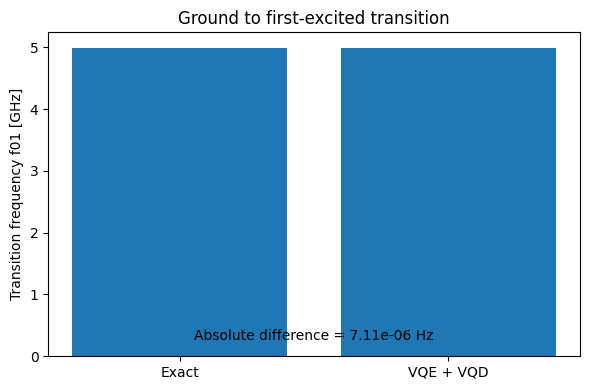

In [22]:
# All figures display inline. This section writes no separate image files.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(
    np.arange(1, len(ground_refinement_history) + 1),
    ground_refinement_history, label="Ground refinement",
)
axes[0].axhline(E0_exact_vqd, color="black", linestyle="--", label="Exact E0")
axes[0].set(xlabel="Optimizer iteration", ylabel="Energy / h [GHz]",
            title="Ground-state refinement")
iterations_vqd = np.arange(1, len(vqd_history["cost"]) + 1)
axes[1].plot(iterations_vqd, vqd_history["cost"], label="Deflated cost")
axes[1].plot(iterations_vqd, vqd_history["energy"], label="Physical energy")
axes[1].axhline(E1_exact_vqd, color="black", linestyle="--", label="Exact E1")
axes[1].set(xlabel="Optimizer iteration", ylabel="Energy / h [GHz]",
            title="First-excited-state VQD")
for ax in axes:
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    ax.legend()
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(n, exact_vectors_vqd[:, 0]**2, "o-", label="Exact ground")
axes[0].plot(n, ground_state_vqd[:d]**2, "x--", label="Refined ground")
axes[0].plot(n, exact_vectors_vqd[:, 1]**2, "o-", label="Exact first excited")
axes[0].plot(n, excited_state_vqd[:d]**2, "x--", label="VQD first excited")
axes[0].set(xlabel="Excess Cooper-pair number n", ylabel="Charge probability",
            title="Ground and excited charge distributions")
axes[0].legend()
axes[1].plot(iterations_vqd, np.maximum(vqd_history["overlap"], 1e-18))
axes[1].set(xlabel="Optimizer iteration", ylabel="Squared ground-state overlap",
            yscale="log", title="Deflation suppresses the ground component")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Exact", "VQE + VQD"], [f01_exact, f01_vqd])
ax.set_ylabel("Transition frequency f01 [GHz]")
ax.set_title("Ground to first-excited transition")
ax.text(
    0.5, 0.05, f"Absolute difference = {1e9 * f01_error:.3g} Hz",
    transform=ax.transAxes, ha="center",
)
fig.tight_layout()
plt.show()


## Simulation results and limitations

| Quantity | Result for the specified inputs |
|---|---:|
| Effective capacitance | 93.312497 fF |
| Charging energy divided by $h$ | 0.207584515 GHz |
| Josephson energy divided by $h$ | 16.346151281 GHz |
| Linear input frequency | 5.210150 GHz |
| Exact ground-to-first-excited frequency at $N=8$ | 4.993277878 GHz |
| VQE plus VQD transition at $N=8$ | 4.993277878 GHz |
| Exact transition at $N=10$ | 4.993277822 GHz |
| Exact-model anharmonicity | -230.550 MHz |

The simulated VQD transition agrees with numerical diagonalization for the same Hamiltonian. Increasing the cutoff from eight to ten changes the exact transition by about 56.3 Hz. The much smaller variational error measures algorithm agreement within the chosen finite basis.

The circuit parameters come from a single-mode LC equivalent. This is an effective reduction of the circuit. Input uncertainty and additional circuit modes can affect the physical prediction. The complete charge ansatz and projector become costly at larger dimensions, and the analytic gradients assume statevector access.

Every figure displays inline.


## Compare the linear mode and quantum transition

The linear input frequency is used with the inductance to infer the effective capacitance. The quantum transition is then obtained from the full cosine Hamiltonian,

$$f_{01}=(E_1-E_0)/h.$$

Compare the linear mode frequency with the exact and VQD transition frequencies. Josephson nonlinearity changes the level spacing. The exact and variational results should agree closely for the same charge model.


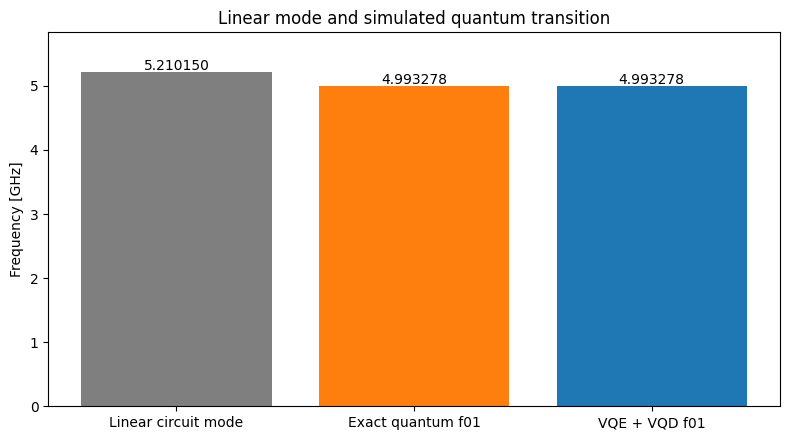

In [23]:
fig, ax = plt.subplots(figsize=(8, 4.5))
frequencies = [f_linear_GHz, f01_exact, f01_vqd]
bars = ax.bar(
    ["Linear circuit mode", "Exact quantum f01", "VQE + VQD f01"],
    frequencies,
    color=["tab:gray", "tab:orange", "tab:blue"],
)
for bar, frequency in zip(bars, frequencies):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        frequency + 0.04,
        f"{frequency:.6f}",
        ha="center",
    )
ax.set_ylim(0, max(frequencies) * 1.12)
ax.set_ylabel("Frequency [GHz]")
ax.set_title("Linear mode and simulated quantum transition")
fig.tight_layout()
plt.show()
